# 01 · Cáncer de mama (Wisconsin) con Keras desde cero
**Deep Learning – UCC.** Meta: **loss < 0.03** y **accuracy > 0.985**. Todos los modelos se entrenan desde cero (sin pre-entrenados).

Dataset: `data/breast_cancer_wisconsin.csv`. Objetivo: `diagnosis` (M = maligno = 1, B = benigno = 0); se ignora la columna `id`.

Reglas que sigue el notebook:
* El **test no se usa para elegir nada** (ni arquitectura, ni hiperparámetros, ni cluster): se elige con validación y CV.
* Escalado y KMeans se ajustan **solo con train** (sin *data leakage*).
* Loss y accuracy se reportan **por separado** en train, validación, test y CV.

> **Ejecutar en Google Colab:** sube la carpeta del proyecto (`data/`, `notebooks/`, `models/`, `results/`) a Colab o móntala desde Drive y ejecuta desde su raíz con `%cd /content/Momento2IA`. Colab ya trae TensorFlow; si falta algo: `!pip install -r requirements.txt`. Las rutas son relativas y funcionan igual desde `notebooks/` o desde la raíz.

## 0. Configuración
Imports agrupados, semilla fija, meta de la actividad y rutas relativas.

In [1]:
import os, json, time, random, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (adjusted_rand_score, log_loss, confusion_matrix, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)          # fija random, numpy y tensorflow
tf.config.experimental.enable_op_determinism()

META_LOSS, META_ACC = 0.03, 0.985
def cumple(loss, acc): return bool(loss < META_LOSS and acc > META_ACC)

# Rutas relativas: funcionan desde notebooks/, desde la raíz del proyecto y en Colab
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DATA_CSV    = os.path.join(ROOT, "data", "breast_cancer_wisconsin.csv")
MODELS_DIR  = os.path.join(ROOT, "models")
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)
assert os.path.exists(DATA_CSV), f"No se encontró {DATA_CSV}. Ejecuta desde notebooks/ o desde la raíz del proyecto."
SUF = "cancer"                              # sufijo de los archivos que genera este notebook
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | semilla {SEED}")

TensorFlow 2.21.0 | Keras 3.15.1 | semilla 42


## 1. Carga y exploración
Forma, tipos, balance de clases y valores faltantes.

In [2]:
raw = pd.read_csv(DATA_CSV)
print("Forma:", raw.shape)
print("Tipos de datos:", raw.dtypes.value_counts().to_dict())
bal = raw["diagnosis"].value_counts().rename("n").to_frame(); bal["%"] = (bal["n"] / len(raw) * 100).round(1)
print("\nBalance de clases:"); display(bal)
print("Valores faltantes totales:", int(raw.isna().sum().sum()))
display(raw.describe().T.head(10))

Forma: (569, 32)
Tipos de datos: {dtype('float64'): 30, dtype('int64'): 1, <StringDtype(storage='python', na_value=nan)>: 1}

Balance de clases:


,n,%
diagnosis,,
B,357,62.7
M,212,37.3


Valores faltantes totales: 0


,count,mean,std,min,25%,50%,75%,max
id,569.0,285.000000,164.400426,1.00000,143.00000,285.00000,427.0000,569.0000
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.1957,0.3040


## 2. Limpieza
Se descarta `id` (no es una variable), se codifica `diagnosis` (M=1, B=0) y se comprueba que no hay filas duplicadas (que podrían caer a la vez en train y en test).

In [3]:
df = raw.drop(columns=["id"]).copy()
df["diagnosis"] = (df["diagnosis"] == "M").astype(int)
print("Filas duplicadas:", int(df.duplicated().sum()), "| faltantes:", int(df.isna().sum().sum()))
FEATURES = [c for c in df.columns if c != "diagnosis"]
NOMBRE_NEG, NOMBRE_POS = "Benigno (B=0)", "Maligno (M=1)"

Filas duplicadas: 0 | faltantes: 0


## 3. Preparación de datos
1. Partición **estratificada 70/15/15** (train / validación / test), semilla fija.
2. **StandardScaler ajustado solo con train** y aplicado a validación y test (si se ajustara con todo, la media y desviación del test se filtrarían al entrenamiento).
3. Se guarda el scaler con `joblib`.

`fit_prep` / `transform_prep` encapsulan el preprocesamiento para repetirlo **dentro de cada fold** en la validación cruzada.

In [4]:
X_all, y_all = df[FEATURES], df["diagnosis"].values
X_tr_raw, X_tmp, y_tr, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va_raw, X_te_raw, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(pd.DataFrame({"filas": [len(y_tr), len(y_va), len(y_te)], "% clase 1": [y_tr.mean()*100, y_va.mean()*100, y_te.mean()*100]},
                   index=["train", "validación", "test"]).round(1))

def fit_prep(X_raw):
    # scaler y KMeans(k=2) ajustados SOLO con los datos recibidos (train)
    scaler = StandardScaler().fit(X_raw)
    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(scaler.transform(X_raw).astype("float32"))
    return dict(scaler=scaler, km=km)

def transform_prep(prep, X_raw, use_cluster=False):
    Xs = prep["scaler"].transform(X_raw)
    if use_cluster:
        Xs = np.column_stack([Xs, prep["km"].predict(Xs.astype("float32"))])
    return Xs.astype("float32")

prep = fit_prep(X_tr_raw)
Xtr_s, Xva_s, Xte_s = (transform_prep(prep, d) for d in (X_tr_raw, X_va_raw, X_te_raw))
print("\nMedia de train tras escalar ≈ 0:", np.abs(Xtr_s.mean(0)).max().round(6),
      "| media de test (no es 0: no se ajustó con él):", np.abs(Xte_s.mean(0)).max().round(3))
joblib.dump(prep["scaler"], os.path.join(MODELS_DIR, f"scaler_{SUF}.pkl"))
joblib.dump(prep, os.path.join(MODELS_DIR, f"prep_{SUF}.pkl"))      # scaler + kmeans
print(f"Guardado models/scaler_{SUF}.pkl y models/prep_{SUF}.pkl")

            filas  % clase 1
train         398       37.2
validación     85       37.6
test           86       37.2



Media de train tras escalar ≈ 0: 0.0 | media de test (no es 0: no se ajustó con él): 0.373
Guardado models/scaler_cancer.pkl y models/prep_cancer.pkl


## 4. Clusterización (KMeans, k=2)
KMeans se ajusta **solo con train**. Se compara con la clase real (tabla cruzada y **Adjusted Rand Index**: 1 = coinciden, ≈0 = azar). Luego se decide **con evidencia** si agregar el cluster como variable: un modelo pequeño con 5 semillas, con y sin la columna, comparado por **loss de validación**. Solo se adopta si la mejora supera la variabilidad entre semillas y la accuracy no empeora.

In [5]:
km = prep["km"]
filas = []
for nombre, Xs, y in [("train", Xtr_s, y_tr), ("validación", Xva_s, y_va), ("test", Xte_s, y_te)]:
    c = km.predict(Xs)
    filas.append((nombre, adjusted_rand_score(y, c), max((c == y).mean(), (c != y).mean())))   # el id del cluster es arbitrario
print(pd.DataFrame(filas, columns=["conjunto", "ARI", "acuerdo cluster↔clase"]).set_index("conjunto").round(3))
print("\nTabla cruzada en train (filas = clase real, columnas = cluster):")
display(pd.crosstab(pd.Series(y_tr, name="clase real"), pd.Series(km.predict(Xtr_s), name="cluster")))

              ARI  acuerdo cluster↔clase
conjunto                                
train       0.644                  0.902
validación  0.693                  0.918
test        0.695                  0.919

Tabla cruzada en train (filas = clase real, columnas = cluster):


cluster,0,1
clase real,,
0,15,235
1,124,24


La decisión de usar o no el cluster como variable se toma en la sección 5.1, una vez definidas las funciones del modelo.

## 5. Modelo
Dos arquitecturas, ambas con **salida sigmoide**, `binary_crossentropy`, **Adam**, **EarlyStopping** y **ReduceLROnPlateau** (sobre `val_loss`):
* **Densa (MLP):** `Dense → Dropout` repetido, con regularización **L2**.
* **Conv1D:** las variables se tratan como una secuencia `(n_variables, 1)`. En datos tabulares no hay orden espacial real, así que la convolución no tiene ventaja natural; se prueba porque la actividad menciona CNN.

`evaluate()` calcula la entropía cruzada **pura** (Keras suma la penalización L2 en `model.evaluate`), que es la loss comparable con la meta 0.03.

In [6]:
def evaluate(model, X, y):
    p = np.clip(model.predict(X, verbose=0).ravel().astype("float64"), 1e-7, 1 - 1e-7)
    return float(log_loss(y, p, labels=[0, 1])), float(((p >= 0.5).astype(int) == y).mean())

def build_dense(n_in, units=(64, 32), dropout=0.3, l2=1e-3, lr=1e-3):
    reg = regularizers.l2(l2) if l2 > 0 else None
    capas = [layers.Input((n_in,))]
    for u in units:
        capas += [layers.Dense(u, activation="relu", kernel_regularizer=reg), layers.Dropout(dropout)]
    capas += [layers.Dense(1, activation="sigmoid")]
    m = keras.Sequential(capas, name="densa")
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_conv(n_in, filters=16, kernel=3, dropout=0.3, l2=1e-3, lr=1e-3):
    reg = regularizers.l2(l2) if l2 > 0 else None
    m = keras.Sequential([
        layers.Input((n_in,)),
        layers.Reshape((n_in, 1)),                                   # variables como secuencia de longitud n_in
        layers.Conv1D(filters, kernel, padding="same", activation="relu", kernel_regularizer=reg),
        layers.MaxPooling1D(2),
        layers.Dropout(dropout),
        layers.Conv1D(filters * 2, kernel, padding="same", activation="relu", kernel_regularizer=reg),
        layers.GlobalAveragePooling1D(),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ], name="conv1d")
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def fit_model(model, Xtr, ytr, Xva, yva, batch=32, epochs=300, patience=25):
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)]
    return model.fit(Xtr, ytr, validation_data=(Xva, yva), batch_size=batch, epochs=epochs, callbacks=cbs, verbose=0)

def build_from_cfg(c, n_in):
    if c["familia"] == "densa":
        return build_dense(n_in, c["units"], c["dropout"], c["l2"], c["lr"])
    return build_conv(n_in, c["filters"], c["kernel"], c["dropout"], c["l2"], c["lr"])

def describe(c):
    return f"Dense{list(c['units'])}" if c["familia"] == "densa" else f"Conv1D[{c['filters']}x{c['kernel']}]"

def history_dict(h): return {k: [float(x) for x in v] for k, v in h.history.items()}

### 5.1 ¿Se agrega el cluster como variable? (decisión con validación)
KMeans es no supervisado: si coincide bien con las clases, la red ya aprende esa frontera con las etiquetas (información redundante); si coincide mal, aporta ruido. La decisión sale de esta prueba, no de la intuición.

In [7]:
def quick(Xtr, Xva, n_seeds=5):
    res = []
    for s in range(n_seeds):
        keras.utils.set_random_seed(SEED + s)
        m = build_dense(Xtr.shape[1], units=(32, 16), dropout=0.2, l2=1e-3)
        fit_model(m, Xtr, y_tr, Xva, y_va)
        res.append(evaluate(m, Xva, y_va))
    r = np.array(res); return r[:, 0], r[:, 1]

ctr, cva = km.predict(Xtr_s), km.predict(Xva_s)
l0, a0 = quick(Xtr_s, Xva_s)
l1, a1 = quick(np.column_stack([Xtr_s, ctr]).astype("float32"), np.column_stack([Xva_s, cva]).astype("float32"))
display(pd.DataFrame({"loss val (media)": [l0.mean(), l1.mean()], "loss val (std)": [l0.std(), l1.std()],
                      "acc val (media)": [a0.mean(), a1.mean()]}, index=["sin cluster", "con cluster"]).round(4))
USE_CLUSTER = bool((l0.mean() - l1.mean() > l0.std()) and (a1.mean() >= a0.mean()))
print("¿Se agrega el cluster como variable? ->", "SÍ" if USE_CLUSTER else "NO",
      f"(mejora de loss {l0.mean() - l1.mean():.4f} vs. std entre semillas {l0.std():.4f})")
Xtr, Xva, Xte = (transform_prep(prep, d, USE_CLUSTER) for d in (X_tr_raw, X_va_raw, X_te_raw))
N_IN = Xtr.shape[1]; print("Variables de entrada del modelo:", N_IN)

,loss val (media),loss val (std),acc val (media)
sin cluster,0.0723,0.0085,0.9835
con cluster,0.0740,0.0071,0.9859


¿Se agrega el cluster como variable? -> NO (mejora de loss -0.0017 vs. std entre semillas 0.0085)
Variables de entrada del modelo: 30


### 5.2 Densa vs. Conv1D (configuración inicial)
Una configuración razonable de cada familia, misma semilla, antes de la búsqueda.

In [8]:
base = {}
for nombre, builder in [("Densa", lambda: build_dense(N_IN, (64, 32), 0.3, 1e-3, 1e-3)),
                        ("Conv1D", lambda: build_conv(N_IN, 16, 3, 0.3, 1e-3, 1e-3))]:
    keras.utils.set_random_seed(SEED)
    m = builder(); h = fit_model(m, Xtr, y_tr, Xva, y_va)
    (ltr, atr), (lva, ava), (lte, ate) = evaluate(m, Xtr, y_tr), evaluate(m, Xva, y_va), evaluate(m, Xte, y_te)
    base[nombre] = dict(modelo=nombre, parámetros=m.count_params(), épocas=len(h.history["loss"]),
                        loss_train=ltr, acc_train=atr, loss_val=lva, acc_val=ava, loss_test=lte, acc_test=ate)
display(pd.DataFrame(base.values()).set_index("modelo").round(4))

,parámetros,épocas,loss_train,acc_train,loss_val,acc_val,loss_test,acc_test
modelo,,,,,,,,
Densa,4097,56,0.0321,0.9925,0.0687,0.9765,0.0291,0.9884
Conv1D,2721,161,0.1852,0.9347,0.1747,0.9176,0.1264,0.9302


## 6. Búsqueda de configuraciones (mejora iterativa)
**Búsqueda aleatoria** (semilla fija) sobre capas, neuronas, dropout, L2, learning rate y batch size, para ambas familias. Cada intento queda en un DataFrame con loss y accuracy en train, validación y test.

⚠️ **El modelo se elige por la loss de VALIDACIÓN.** Las columnas de test son solo informativas y no intervienen en ninguna decisión. Como elegir el mejor entre muchos intentos puede sobreajustar a una validación pequeña, después se confirma con validación cruzada (sección 7).

In [9]:
rng = random.Random(SEED)
configs = []
for _ in range(18):
    configs.append(dict(familia="densa", units=rng.choice([(32,), (64,), (64, 32), (128, 64), (128, 64, 32)]),
                        dropout=rng.choice([0.0, 0.1, 0.2, 0.3, 0.4]), l2=rng.choice([0.0, 1e-4, 1e-3, 1e-2]),
                        lr=rng.choice([3e-4, 1e-3, 3e-3]), batch=rng.choice([16, 32, 64])))
for _ in range(8):
    configs.append(dict(familia="conv1d", filters=rng.choice([8, 16, 32]), kernel=rng.choice([3, 5]),
                        dropout=rng.choice([0.1, 0.2, 0.3, 0.4]), l2=rng.choice([0.0, 1e-4, 1e-3]),
                        lr=rng.choice([1e-3, 3e-3]), batch=rng.choice([16, 32, 64])))

registro, mejor = [], dict(loss_val=np.inf)
for i, c in enumerate(configs):
    keras.utils.set_random_seed(SEED)
    m = build_from_cfg(c, N_IN); t0 = time.time()
    h = fit_model(m, Xtr, y_tr, Xva, y_va, batch=c["batch"])
    (ltr, atr), (lva, ava), (lte, ate) = evaluate(m, Xtr, y_tr), evaluate(m, Xva, y_va), evaluate(m, Xte, y_te)
    registro.append(dict(id=i, familia=c["familia"], arquitectura=describe(c), dropout=c["dropout"], l2=c["l2"], lr=c["lr"],
                         batch=c["batch"], épocas=len(h.history["loss"]), loss_train=ltr, acc_train=atr,
                         loss_val=lva, acc_val=ava, loss_test=lte, acc_test=ate, seg=round(time.time() - t0, 1)))
    if lva < mejor["loss_val"]:                       # SELECCIÓN SOLO CON VALIDACIÓN
        mejor = dict(loss_val=lva, cfg=c, model=m, hist=h, id=i)

res = pd.DataFrame(registro)
pd.set_option("display.width", 250, "display.max_columns", 30)
display(res.sort_values("loss_val").round(4).reset_index(drop=True))
cfg_f, final, hist_final = mejor["cfg"], mejor["model"], mejor["hist"]
print(f"\nMejor configuración según loss de VALIDACIÓN: intento #{mejor['id']} -> {describe(cfg_f)}  {cfg_f}")
res.to_csv(os.path.join(RESULTS_DIR, f"busqueda_{SUF}.csv"), index=False)

,id,familia,arquitectura,dropout,l2,lr,batch,épocas,loss_train,acc_train,loss_val,acc_val,loss_test,acc_test,seg
0,3,densa,"Dense[128, 64, 32]",0.4,0.0000,0.0030,16,29,0.0575,0.9749,0.0604,0.9882,0.0164,1.0000,13.3
1,14,densa,"Dense[64, 32]",0.0,0.0001,0.0030,64,31,0.0613,0.9824,0.0648,0.9882,0.0328,1.0000,11.5
2,5,densa,"Dense[64, 32]",0.0,0.0001,0.0030,32,29,0.0582,0.9874,0.0655,0.9882,0.0347,1.0000,10.9
3,8,densa,"Dense[64, 32]",0.4,0.0010,0.0003,64,165,0.0479,0.9899,0.0666,0.9765,0.0296,0.9884,41.2
4,6,densa,"Dense[64, 32]",0.2,0.0001,0.0003,32,63,0.0612,0.9849,0.0667,0.9882,0.0367,1.0000,19.6
5,13,densa,"Dense[64, 32]",0.1,0.0010,0.0010,16,43,0.0269,0.9925,0.0701,0.9765,0.0304,0.9884,16.1
6,4,densa,"Dense[128, 64, 32]",0.3,0.0001,0.0010,64,38,0.0587,0.9824,0.0709,0.9882,0.0266,1.0000,13.6
7,1,densa,Dense[64],0.0,0.0000,0.0030,32,36,0.0504,0.9925,0.0744,0.9765,0.0415,0.9884,11.0
8,9,densa,"Dense[128, 64]",0.4,0.0000,0.0010,16,35,0.0461,0.9874,0.0744,0.9882,0.0299,0.9884,14.1
9,2,densa,Dense[32],0.0,0.0000,0.0003,16,106,0.0518,0.9899,0.0754,0.9882,0.0383,1.0000,32.6



Mejor configuración según loss de VALIDACIÓN: intento #3 -> Dense[128, 64, 32]  {'familia': 'densa', 'units': (128, 64, 32), 'dropout': 0.4, 'l2': 0.0, 'lr': 0.003, 'batch': 16}


## 7. Validación cruzada estratificada (5 folds)
Con la mejor configuración, sobre **train + validación** (el test queda intacto). En **cada fold** se vuelven a ajustar scaler y KMeans solo con la parte de entrenamiento, y un 10 % de esa parte se usa para el EarlyStopping. La métrica se mide en el fold que quedó fuera. Se reporta **media ± desviación**.

In [10]:
X_dev_raw = pd.concat([X_tr_raw, X_va_raw]); y_dev = np.concatenate([y_tr, y_va])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
splits_dev = list(skf.split(X_dev_raw, y_dev))
cv_rows = []
for k, (itr, iho) in enumerate(splits_dev, 1):
    Xa, Xo = X_dev_raw.iloc[itr], X_dev_raw.iloc[iho]; ya, yo = y_dev[itr], y_dev[iho]
    Xa1, Xa2, ya1, ya2 = train_test_split(Xa, ya, test_size=0.10, stratify=ya, random_state=SEED)
    p = fit_prep(Xa1)
    A1, A2, O = (transform_prep(p, d, USE_CLUSTER) for d in (Xa1, Xa2, Xo))
    keras.utils.set_random_seed(SEED)
    m = build_from_cfg(cfg_f, A1.shape[1])
    fit_model(m, A1, ya1, A2, ya2, batch=cfg_f["batch"])
    l, a = evaluate(m, O, yo); cv_rows.append(dict(fold=k, loss=l, accuracy=a))
cv = pd.DataFrame(cv_rows).set_index("fold"); display(cv.round(4))
CV = dict(loss_mean=float(cv.loss.mean()), loss_std=float(cv.loss.std()), acc_mean=float(cv.accuracy.mean()), acc_std=float(cv.accuracy.std()))
print(f"CV 5 folds -> loss = {CV['loss_mean']:.4f} ± {CV['loss_std']:.4f} | accuracy = {CV['acc_mean']:.4f} ± {CV['acc_std']:.4f}")

,loss,accuracy
fold,,
1,0.1542,0.9381
2,0.1175,0.9691
3,0.0490,0.9794
4,0.0502,0.9896
5,0.3183,0.9583


CV 5 folds -> loss = 0.1378 ± 0.1105 | accuracy = 0.9669 ± 0.0198


## 8. Modelos de referencia (scikit-learn)
Regresión Logística, SVM RBF, Random Forest y Gradient Boosting con **los mismos splits** y el mismo preprocesamiento, con hiperparámetros por defecto razonables (sin ajustar con test). Sirven para saber si el límite lo pone el dataset o la arquitectura. CV con los mismos 5 folds de la sección 7.

In [11]:
refs = {
    "Regresión Logística": lambda: LogisticRegression(max_iter=5000),
    "SVM RBF":             lambda: SVC(kernel="rbf", probability=True, random_state=SEED),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting":   lambda: GradientBoostingClassifier(random_state=SEED),
}
ref_rows = []
for nombre, mk in refs.items():
    clf = mk().fit(Xtr, y_tr)
    row = {"modelo": nombre}
    for k, X, y in [("train", Xtr, y_tr), ("val", Xva, y_va), ("test", Xte, y_te)]:
        p = np.clip(clf.predict_proba(X)[:, 1], 1e-7, 1 - 1e-7)
        row[f"loss_{k}"] = log_loss(y, p, labels=[0, 1]); row[f"acc_{k}"] = ((p >= 0.5).astype(int) == y).mean()
    cvr = cross_validate(make_pipeline(StandardScaler(), mk()), X_dev_raw, y_dev, cv=splits_dev, scoring={"acc": "accuracy", "ll": "neg_log_loss"})
    row.update(cv_loss=-cvr["test_ll"].mean(), cv_loss_std=cvr["test_ll"].std(), cv_acc=cvr["test_acc"].mean(), cv_acc_std=cvr["test_acc"].std())
    ref_rows.append(row)
ref = pd.DataFrame(ref_rows).set_index("modelo")
display(ref.round(4))
ref.to_csv(os.path.join(RESULTS_DIR, f"referencia_sklearn_{SUF}.csv"))

,loss_train,acc_train,loss_val,acc_val,loss_test,acc_test,cv_loss,cv_loss_std,cv_acc,cv_acc_std
modelo,,,,,,,,,,
Regresión Logística,0.0566,0.9874,0.0848,0.9647,0.0504,0.9767,0.0874,0.0376,0.9649,0.0303
SVM RBF,0.0535,0.9874,0.0947,0.9647,0.0564,0.9767,0.0897,0.0395,0.9690,0.0196
Random Forest,0.0342,1.0000,0.1258,0.9647,0.0822,0.9884,0.1896,0.1787,0.9586,0.0253
Gradient Boosting,0.0021,1.0000,0.1314,0.9529,0.0784,0.9767,0.1193,0.0872,0.9627,0.0250


## 9. Reporte honesto
Se reporta cada conjunto **por separado** y se indica en cuál se cumple **loss < 0.03 y accuracy > 0.985**.
* **Train:** el modelo ya vio esos datos; un valor excelente aquí **no** demuestra buen modelo (puede ser sobreajuste).
* **Validación:** se usó para elegir modelo y parar el entrenamiento → algo optimista.
* **Test:** única estimación imparcial, pero con ~86 muestras: cada error cuesta más de 1 punto de accuracy.
* **CV:** la estimación más estable (train + validación; el test sigue aparte).

In [12]:
rows = {}
for nombre, X, y in [("train", Xtr, y_tr), ("validación", Xva, y_va), ("test", Xte, y_te)]:
    l, a = evaluate(final, X, y)
    rows[nombre] = dict(n=len(y), loss=l, accuracy=a, **{"loss<0.03": l < META_LOSS, "acc>0.985": a > META_ACC, "CUMPLE META": cumple(l, a)})
rows["CV 5 folds (media)"] = dict(n=len(y_dev), loss=CV["loss_mean"], accuracy=CV["acc_mean"], **{"loss<0.03": CV["loss_mean"] < META_LOSS,
                                  "acc>0.985": CV["acc_mean"] > META_ACC, "CUMPLE META": cumple(CV["loss_mean"], CV["acc_mean"])})
tabla = pd.DataFrame(rows).T
display(tabla.assign(loss=tabla.loss.astype(float).round(4), accuracy=tabla.accuracy.astype(float).round(4)))
print(f"Modelo final: {describe(cfg_f)} | {cfg_f}")
for k, r in rows.items():
    print(f"- {k:19s}: loss={r['loss']:.4f}, acc={r['accuracy']:.4f} -> {'CUMPLE' if r['CUMPLE META'] else 'NO cumple'} la meta")
c_tr, c_va, c_te, c_cv = (rows[k]["CUMPLE META"] for k in ("train", "validación", "test", "CV 5 folds (media)"))
if c_te and c_va and c_cv:        veredicto = "La meta SE CUMPLE en validación, test y CV."
elif c_te and c_va:               veredicto = "La meta se cumple en validación y test, pero NO en la CV (estimación más estable): resultado frágil."
elif c_tr and not (c_va or c_te): veredicto = "La meta SOLO se cumple en ENTRENAMIENTO (sobreajuste)."
elif c_te or c_va:                veredicto = f"La meta se cumple solo en {'test' if c_te else 'validación'}, no en ambos, y no en la CV."
else:                             veredicto = "La meta NO se cumple en ningún conjunto (train, validación, test ni CV)."
print("\nVEREDICTO:", veredicto)
print(f"Con {len(y_te)} muestras de test, cada error equivale a {100/len(y_te):.2f} puntos de accuracy: acc>0.985 exige ≤{int(np.floor((1-META_ACC)*len(y_te)))} error(es).")

,n,loss,accuracy,loss<0.03,acc>0.985,CUMPLE META
train,398,0.0575,0.9749,False,False,False
validación,85,0.0604,0.9882,False,True,False
test,86,0.0164,1.0000,True,True,True
CV 5 folds (media),483,0.1378,0.9669,False,False,False


Modelo final: Dense[128, 64, 32] | {'familia': 'densa', 'units': (128, 64, 32), 'dropout': 0.4, 'l2': 0.0, 'lr': 0.003, 'batch': 16}
- train              : loss=0.0575, acc=0.9749 -> NO cumple la meta
- validación         : loss=0.0604, acc=0.9882 -> NO cumple la meta
- test               : loss=0.0164, acc=1.0000 -> CUMPLE la meta
- CV 5 folds (media) : loss=0.1378, acc=0.9669 -> NO cumple la meta

VEREDICTO: La meta se cumple solo en test, no en ambos, y no en la CV.
Con 86 muestras de test, cada error equivale a 1.16 puntos de accuracy: acc>0.985 exige ≤1 error(es).


In [13]:
# Comparativa global: red Keras vs. modelos de referencia (mismos splits)
l_ = {k: evaluate(final, X, y) for k, X, y in [("train", Xtr, y_tr), ("val", Xva, y_va), ("test", Xte, y_te)]}
glob = [dict(modelo="Keras red única", **{f"loss_{k}": v[0] for k, v in l_.items()}, **{f"acc_{k}": v[1] for k, v in l_.items()},
             cv_loss=CV["loss_mean"], cv_acc=CV["acc_mean"], cv_acc_std=CV["acc_std"])]
for n, r in ref.iterrows():
    glob.append(dict(modelo=n, **{c: r[c] for c in ["loss_train", "acc_train", "loss_val", "acc_val", "loss_test", "acc_test", "cv_loss", "cv_acc", "cv_acc_std"]}))
glob = pd.DataFrame(glob).set_index("modelo")
for k, (lc, ac) in {"meta en val": ("loss_val", "acc_val"), "meta en test": ("loss_test", "acc_test"), "meta en CV": ("cv_loss", "cv_acc")}.items():
    glob[k] = [cumple(a, b) for a, b in zip(glob[lc], glob[ac])]
display(glob.round(4))
glob.to_csv(os.path.join(RESULTS_DIR, f"comparativa_modelos_{SUF}.csv"))

,loss_train,loss_val,loss_test,acc_train,acc_val,acc_test,cv_loss,cv_acc,cv_acc_std,meta en val,meta en test,meta en CV
modelo,,,,,,,,,,,,
Keras red única,0.0575,0.0604,0.0164,0.9749,0.9882,1.0000,0.1378,0.9669,0.0198,False,True,False
Regresión Logística,0.0566,0.0848,0.0504,0.9874,0.9647,0.9767,0.0874,0.9649,0.0303,False,False,False
SVM RBF,0.0535,0.0947,0.0564,0.9874,0.9647,0.9767,0.0897,0.9690,0.0196,False,False,False
Random Forest,0.0342,0.1258,0.0822,1.0000,0.9647,0.9884,0.1896,0.9586,0.0253,False,False,False
Gradient Boosting,0.0021,0.1314,0.0784,1.0000,0.9529,0.9767,0.1193,0.9627,0.0250,False,False,False


In [14]:
# Test: matriz de confusión, precision, recall y F1
p_te = (final.predict(Xte, verbose=0).ravel() >= 0.5).astype(int)
cm = confusion_matrix(y_te, p_te)
TEST_REP = dict(precision=float(precision_score(y_te, p_te)), recall=float(recall_score(y_te, p_te)), f1=float(f1_score(y_te, p_te)),
                tn=int(cm[0, 0]), fp=int(cm[0, 1]), fn=int(cm[1, 0]), tp=int(cm[1, 1]))
print(classification_report(y_te, p_te, target_names=[NOMBRE_NEG, NOMBRE_POS], digits=4))
print(f"Falsos negativos en test: {TEST_REP['fn']} (tumores malignos que el modelo NO detecta)")

               precision    recall  f1-score   support

Benigno (B=0)     1.0000    1.0000    1.0000        54
Maligno (M=1)     1.0000    1.0000    1.0000        32

     accuracy                         1.0000        86
    macro avg     1.0000    1.0000    1.0000        86
 weighted avg     1.0000    1.0000    1.0000        86

Falsos negativos en test: 0 (tumores malignos que el modelo NO detecta)


### Lectura de los resultados (para la sustentación)
* Las clases son casi separables con las 30 variables, así que se esperan accuracies de ~96–99 %. Alcanzar **a la vez** loss < 0.03 en validación/test es muy exigente: una sola predicción segura-pero-equivocada sube mucho la entropía cruzada media, y con ~85 muestras por conjunto un error ya mueve la accuracy más de 1 punto.
* Una cifra perfecta en test con pocas muestras puede ser **suerte de la partición**; por eso se contrasta con la **CV**, que es una estimación más estable.
* Si un modelo muestra loss ≈ 0 y accuracy ≈ 1 en **train** pero peor en validación/test, eso es **sobreajuste**, no un resultado válido.
* Las cifras exactas de esta ejecución son las de las tablas y el VEREDICTO de arriba.

## 10. Gráficas
Loss y accuracy de entrenamiento vs. validación por época (la loss de Keras incluye la penalización L2) y matriz de confusión en test.

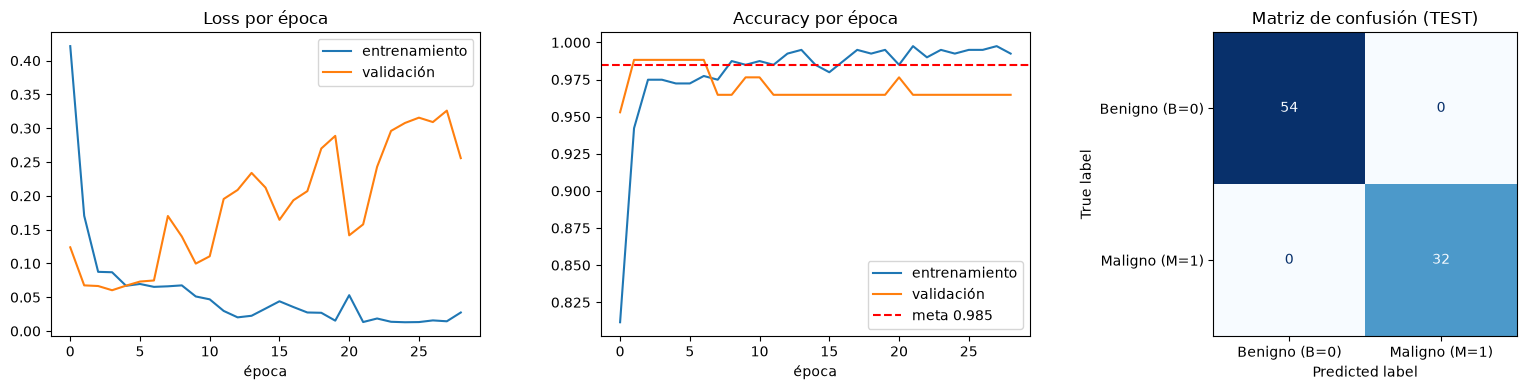

In [15]:
h = hist_final.history
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(h["loss"], label="entrenamiento"); ax[0].plot(h["val_loss"], label="validación")
ax[0].set_title("Loss por época"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(h["accuracy"], label="entrenamiento"); ax[1].plot(h["val_accuracy"], label="validación")
ax[1].axhline(META_ACC, color="r", ls="--", label="meta 0.985"); ax[1].set_title("Accuracy por época"); ax[1].set_xlabel("época"); ax[1].legend()
ConfusionMatrixDisplay(cm, display_labels=[NOMBRE_NEG, NOMBRE_POS]).plot(ax=ax[2], colorbar=False, cmap="Blues")
ax[2].set_title("Matriz de confusión (TEST)")
plt.tight_layout(); plt.show()

## 11. Guardado
En `models/` y `results/`: el modelo `.keras`, el historial de entrenamiento (`.json` y `.csv`, para graficar después) y un resumen de resultados (`resultados_cancer.json`). El scaler y la tabla de búsqueda ya se guardaron antes.

In [16]:
final.save(os.path.join(MODELS_DIR, f"model_{SUF}.keras"))
hd = history_dict(hist_final)
json.dump(hd, open(os.path.join(RESULTS_DIR, f"history_{SUF}.json"), "w"), indent=1)
pd.DataFrame(hd).to_csv(os.path.join(RESULTS_DIR, f"history_{SUF}.csv"), index_label="epoch")

resultados = dict(
    dataset=SUF, modelo=describe(cfg_f), config={k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg_f.items()},
    usa_cluster=USE_CLUSTER, n_features=N_IN, n_train=len(y_tr), n_val=len(y_va), n_test=len(y_te),
    train={k: float(rows["train"][k]) for k in ("loss", "accuracy")}, val={k: float(rows["validación"][k]) for k in ("loss", "accuracy")},
    test={k: float(rows["test"][k]) for k in ("loss", "accuracy")}, cv=CV,
    cumple=dict(train=c_tr, val=c_va, test=c_te, cv=c_cv), test_report=TEST_REP, veredicto=veredicto, baseline=base,
)
json.dump(resultados, open(os.path.join(RESULTS_DIR, f"resultados_{SUF}.json"), "w"), indent=1, default=float)
print("models/ :", sorted(f for f in os.listdir(MODELS_DIR) if SUF in f))
print("results/:", sorted(f for f in os.listdir(RESULTS_DIR) if f.endswith(f"{SUF}.json") or f.endswith(f"{SUF}.csv")))

models/ : ['model_cancer.keras', 'prep_cancer.pkl', 'scaler_cancer.pkl']
results/: ['busqueda_cancer.csv', 'comparativa_modelos_cancer.csv', 'history_cancer.csv', 'history_cancer.json', 'referencia_sklearn_cancer.csv', 'resultados_cancer.json']


## 12. Predicción con `model.predict`
Tres pacientes del **conjunto de test** (por construcción no están en train ni en validación). Se eligen de forma fija: el primer maligno, el primer benigno y un tercero al azar con semilla; no se escogen según lo bien que los clasifique el modelo. Se aplica el mismo preprocesamiento (scaler ajustado con train).

In [17]:
idx_pos = np.where(y_te == 1)[0][0]; idx_neg = np.where(y_te == 0)[0][0]
idx_3 = int(np.random.RandomState(SEED).choice([i for i in range(len(y_te)) if i not in (idx_pos, idx_neg)]))
ej = X_te_raw.iloc[[idx_pos, idx_neg, idx_3]]
proba = final.predict(transform_prep(prep, ej, USE_CLUSTER), verbose=0).ravel()
real = y_te[[idx_pos, idx_neg, idx_3]]
out = pd.DataFrame({"paciente": ["A", "B", "C"], "mean radius": ej["mean radius"].values, "mean area": ej["mean area"].values,
                    "worst concave points": ej["worst concave points"].values,
                    "probabilidad de malignidad": proba.round(4), "clase predicha": np.where(proba >= 0.5, NOMBRE_POS, NOMBRE_NEG),
                    "clase real": np.where(real == 1, NOMBRE_POS, NOMBRE_NEG)})
display(out)

,paciente,mean radius,mean area,worst concave points,probabilidad de malignidad,clase predicha,clase real
0,A,19.59,1214.0,0.22470,1.0,Maligno (M=1),Maligno (M=1)
1,B,10.17,311.9,0.02579,0.0,Benigno (B=0),Benigno (B=0)
2,C,23.29,1685.0,0.27330,1.0,Maligno (M=1),Maligno (M=1)
